## Exercise: Guided ML Implementation

We'll build an end-to-end machine learning workflow in Jupyter, one stage at a time.

### Stage 1 — Environment and Dataset Setup
We'll start with the California housing regression dataset, following the structure of your uploaded Lab-End_to_end_Machine_Learning_Project. This is a good starting point because the lab covers sampling strategies, EDA, feature engineering, preprocessing pipelines, regression models, and cross-validation.

Later, your Titanic assignment will provide a useful classification counterpart.

**Your first task**

Open your Docker/Jupyter environment and create a new notebook called: `Chapter04_End_to_End_ML.ipynb`

Then, without copying a complete solution, try to write Python code that accomplishes the following:
1. Import `pandas`, `numpy`, and `matplotlib.pyplot`.
2. Load the California housing dataset, following the loading instructions in your course lab.
3. Store the data in a DataFrame called housing.
4. Display the first five rows.
5. Print the dataset's shape and column names.

Important: Don't preprocess or split anything yet. We want to inspect the original dataset first.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

def load_housing_data(path):
    csv_path = os.path.join("datasets", path)
    return pd.read_csv(csv_path)

filename = "housing.csv"
housing = load_housing_data(filename)
print(housing.shape)
print(housing.columns)
print(housing.head())

(20640, 10)
Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='str')
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0 

### Stage 2 — Exploratory Data Analysis

After correcting `.columns`, run the cell again and verify that the column names and first five rows appear.

Then I want you to write code that answers these four questions:
1. What are the data types of the features?
2. Which columns contain missing values, and how many?
3. What are the summary statistics (mean, standard deviation, min, max, etc.) of the numerical features?
4. What are the unique categories in `ocean_proximity`, and how frequently does each appear?

Hint: You've already used `.head()` and `.shape()`. Pandas has similarly convenient methods for each of these tasks.

In [2]:
housing.info()
print(housing.isna().sum())
print(housing.describe())
print(housing['ocean_proximity'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype:

### 2.1 — EDA Visualizations
Now I want you to investigate distributions, relationships, and geographic patterns.

Write Python code to accomplish these three tasks:

**Task A — Numerical feature distributions**

Create histograms for the numerical columns.

Hints: Pandas provides `.hist()`, and Matplotlib can control the figure size and layout.

Investigate whether distributions are symmetric or skewed, and whether any variables appear capped.

**Task B — Feature relationships**

Calculate the Pearson correlation of each numerical variable with `median_house_value`, then sort the results from highest to lowest.

Hints: Use `.corr()`, select the target column, and `.sort_values()`.

Remember that correlation measures linear association, not causation.

**Task C — Geographic visualization**

Create a scatterplot where:
- X-axis: `longitude`
- Y-axis: `latitude`
- Point color: `median_house_value`
- Point transparency: approximately `0.3`
Hints: Use `housing.plot(kind="scatter", ...)` and pass the target column to `c`.

This will help you investigate whether housing prices exhibit geographic patterns.

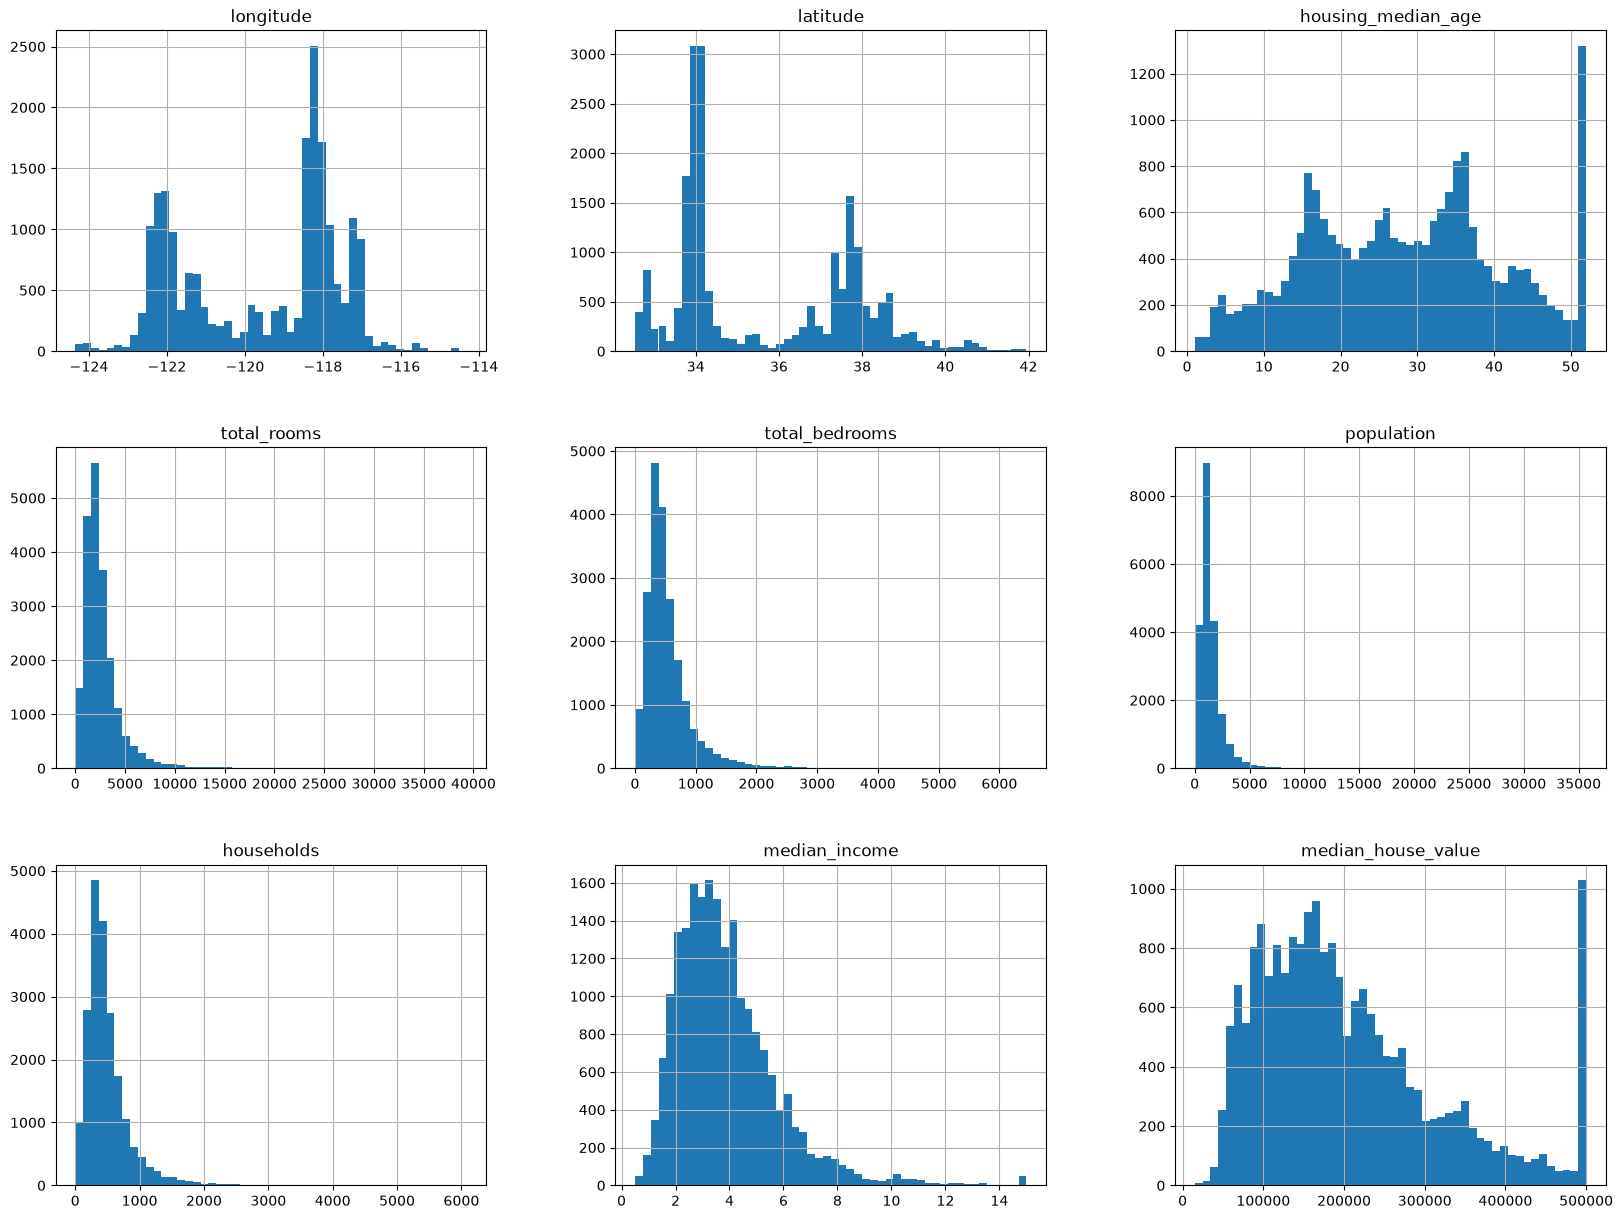

In [3]:
# Task A: Numerical feature distributions
housing.hist(bins=50, figsize=(20, 15))
plt.show()

In [4]:
# Task B: Feature relationships
target_corr = housing.corr(numeric_only=True)['median_house_value'].sort_values(ascending=False)
print(target_corr)

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64


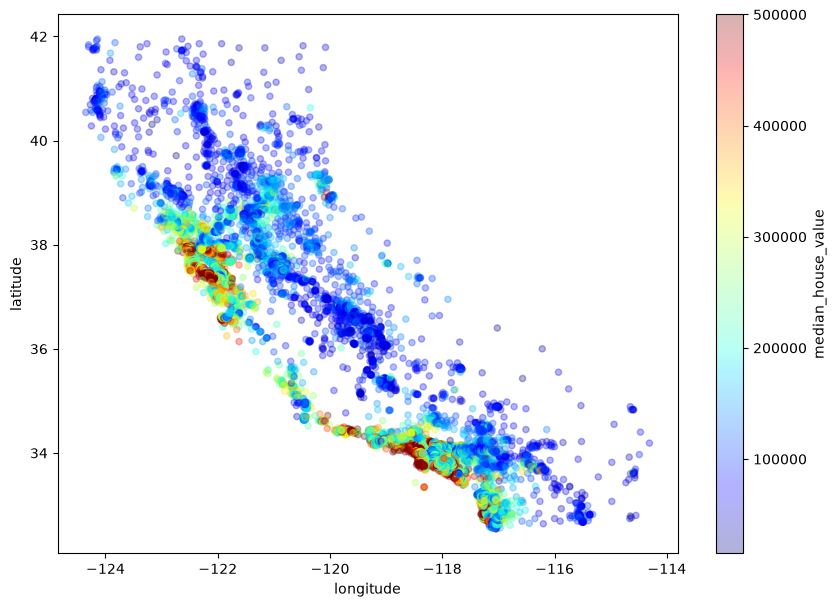

In [5]:
# Task C: Geographic visualization
housing.plot(
    kind="scatter",
    x="longitude",
    y="latitude",
    c="median_house_value",
    cmap="jet",
    alpha=0.3,
    figsize=(10, 7),
    colorbar=True
)

plt.show()

/tmp/ipykernel_73315/2820655683.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  cbar.ax.set_yticklabels(


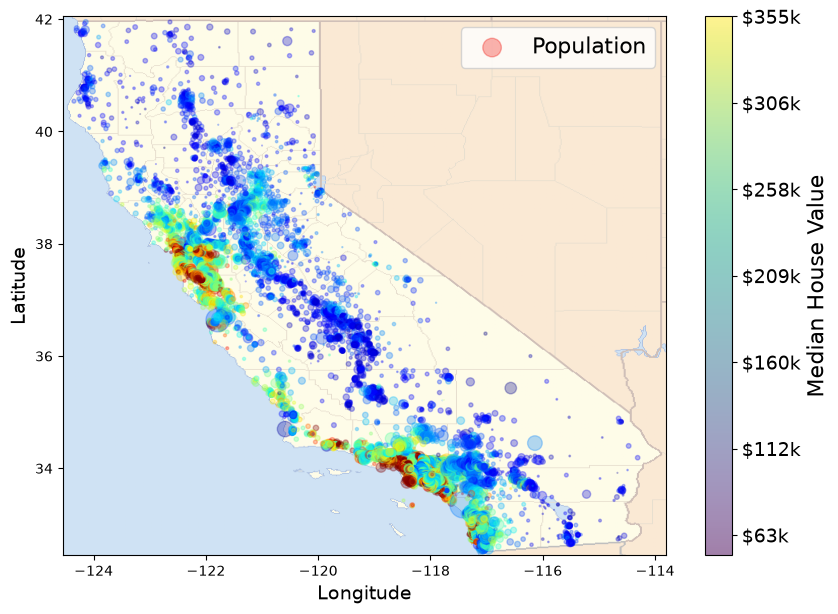

In [6]:
# Better visualization
import matplotlib.image as mpimg

california_img = mpimg.imread('./images/california.png')
ax = housing.plot(
    kind='scatter', 
    x='longitude', 
    y='latitude', 
    figsize=(10, 7),
    s=housing['population']/100,
    label='Population',
    c='median_house_value',
    cmap=plt.get_cmap('jet'),
    colorbar=False,
    alpha=0.3
)

plt.imshow(
    california_img, 
    extent=[-124.55, -113.80, 32.45, 42.05], 
    alpha=0.5
)

plt.ylabel(
    "Latitude", 
    fontsize=14
)

plt.xlabel(
    "Longitude", 
    fontsize=14
)

prices = housing["median_house_value"]
tick_values = np.linspace(
    prices.min(), 
    prices.max(), 
    11
)

cbar = plt.colorbar()
cbar.ax.set_yticklabels(
    ["$%dk"%(round(v/1000)) for v in tick_values], 
    fontsize=14
)

cbar.set_label(
    'Median House Value', 
    fontsize=16
)

plt.legend(fontsize=16)
plt.show()

**Task A — Your interpretation is correct**

You correctly identified:
- Capped features: `housing_median_age` (52 years) and `median_house_value` ($500,001).
- Right-skewed features: `total_rooms`, `total_bedrooms`, `population`, `households`, and `median_income`.

These observations have modeling implications.

For example, strongly skewed numerical features might benefit from a logarithmic transformation. Capped target values are more complicated because they represent incomplete information about the actual values above the cap.

We won't apply transformations yet. We're identifying potential preprocessing decisions.

**Task B — Correct**

Your results show:

Strongest correlations with median house value

![](./images/chart-bar.png)

`median_income` has the strongest positive linear correlation with `median_house_value`, approximately 0.688.

That's a moderately strong positive relationship.

However, notice something interesting: `total_rooms` has a correlation of only 0.134.

That doesn't necessarily mean the number of rooms is unimportant. It may mean that the raw number of rooms is less informative than a derived feature, such as:
$$
\text{Rooms per household}=\frac{\text{total rooms}}{\text{households}}
$$

This is exactly why feature engineering can improve predictive performance.

**Task C — Correct**

Your plot shows concentrations of higher-priced housing around the San Francisco Bay Area and parts of coastal Southern California, including the Los Angeles and San Diego regions.

This suggests that location is an important predictor, even though latitude and longitude individually have weak linear correlations with house value.

That's an important ML insight: a feature can have weak individual linear correlation but still be highly useful when combined with other features or modeled nonlinearly.


### Stage 3 — Train/Test Splitting

**Objective**

Create an untouched test set that will provide a reliable estimate of how our final model generalizes.

We're going to compare random sampling with stratified sampling.

**Why stratification matters**

Our dataset has 20,640 observations, but different income levels aren't represented equally.

Because `median_income` is strongly associated with our target, we want the training and test sets to have similar income distributions.

Stratification helps preserve those proportions.

**Your task — Part A: Random splitting**

Using `sklearn.model_selection.train_test_split`, write code that:
1. Splits `housing` into 80% training and 20% testing.
2. Sets `random_state=42` for reproducibility.
3. Stores the results as `train_set` and `test_set`.
4. Prints the shapes of both datasets.

Hint: The function returns two DataFrames when you pass one DataFrame as input.

**Your task — Part B: Income stratification**

We'll create a temporary categorical feature called `income_cat`, representing income brackets.

Use these boundaries:
| Category | Median income range |
| :--- | :--- |	
| 1 | 0–1.5 |
| 2 | 1.5–3.0 |
| 3 | 3.0–4.5 |
| 4 | 4.5–6.0 |
| 5 | Above 6.0 |

To create the categories, investigate `pd.cut()`.

Then use `train_test_split()` again, this time with its stratify parameter set to the income category column.

Use different variable names for the stratified training and test sets so you can compare them with the random split.

Important: `income_cat` is a temporary sampling aid, not a new predictor. We'll remove it from the modeling data after splitting.

**Your task — Part C: Compare distributions**

Calculate the percentage of observations belonging to each income category in:
- The full dataset.
- The randomly sampled test set.
- The stratified test set.
Use `value_counts(normalize=True)` to calculate proportions.


In [7]:
# Random splitting
from sklearn.model_selection import train_test_split

housing['income_cat'] = pd.cut(
    housing['median_income'], 
    bins=[0, 1.5, 3.0, 4.5, 6.0, np.inf], 
    labels=[1, 2, 3, 4, 5]
)

housing['income_cat'].head()

train_set, test_set = train_test_split(
    housing, test_size=0.2, random_state=42
)

print(train_set.shape)
print(test_set.shape)

(16512, 11)
(4128, 11)


In [8]:
# Income stratification
strat_train_set, strat_test_set = train_test_split(
    housing, test_size=0.2, random_state=42, stratify=housing['income_cat']
)

In [9]:
# Compare distributions
full_dist = housing['income_cat'].value_counts(normalize=True) * 100
rand_dist = test_set['income_cat'].value_counts(normalize=True) * 100
strat_dist = strat_test_set['income_cat'].value_counts(normalize=True) * 100

comparison = pd.DataFrame({
    "Full Dataset": full_dist,
    "Random Test": rand_dist,
    "Stratified Test": strat_dist
})

print(comparison.sort_index())

            Full Dataset  Random Test  Stratified Test
income_cat                                            
1               3.982558     4.021318         3.997093
2              31.884690    32.437016        31.879845
3              35.058140    35.852713        35.053295
4              17.630814    16.739341        17.635659
5              11.443798    10.949612        11.434109


### Stage 4 — Preprocessing and Feature Engineering

This is one of the most important stages of the project. We're going to build a reusable preprocessing system using scikit-learn.

**Step 1 — Prepare the training data**

We will use your stratified training set, not the random training set.

First, remove the temporary `income_cat` column and separate the features from the target.

``housing_train = strat_train_set.drop(
    columns=["income_cat", "median_house_value"]
)``

`housing_labels = strat_train_set["median_house_value"].copy()`

Why?
- `income_cat` was created solely for stratification.
- `median_house_value` is our target, so it must not appear among the predictors.
- We preserve the original stratified test set for final evaluation.

**Step 2 — Identify preprocessing requirements**

From your EDA, we know:
| Feature type | Problem | Planned transformation
| :--- | :--- | :--- |
| Numerical | Missing `total_bedrooms` values | `SimpleImputer(strategy="median")` |
| Numerical | Different feature scales | `StandardScaler()` |
| Categorical | `ocean_proximity` contains strings | `OneHotEncoder(handle_unknown="ignore")` |

We'll use a ColumnTransformer to apply different transformations to numerical and categorical features.

**Step 3 — Your coding task**

I want you to construct the preprocessing pipeline yourself.

**Part A — Numerical pipeline**

Import `Pipeline`, `SimpleImputer`, and `StandardScaler`.

Create a pipeline named `num_pipeline` containing two sequential steps:
1. An imputer that replaces missing values with the median.
2. A standard scaler.

**Part B — Categorical preprocessing**

Import `OneHotEncoder`.

Create a categorical transformer that converts `ocean_proximity` into one-hot encoded features. Set `handle_unknown="ignore"` so an unfamiliar category at prediction time doesn't cause an error.

**Part C — Combine transformations**

Import `ColumnTransformer`.

Identify your numerical and categorical column names, then construct a `ColumnTransformer` named `preprocessing` that applies the appropriate transformations.

**Part D — Fit and transform**

Call:

`housing_prepared = preprocessing.fit_transform(housing_train)`

Then inspect the resulting shape.

In [10]:
# Prepare training data
housing_train = strat_train_set.drop(
    columns=['income_cat', 'median_house_value']
)

housing_labels = strat_train_set['median_house_value'].copy()

In [11]:
# Numerical pipeline
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

numerical_features = housing_train.select_dtypes(
    include=np.number
).columns.tolist()

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [12]:
# Categorical pipeline
from sklearn.preprocessing import OneHotEncoder

categorical_features = ['ocean_proximity']

categorical_pipeline = Pipeline([
    ('ohe', OneHotEncoder(handle_unknown='ignore'))
])

In [13]:
# Combine transformations
from sklearn.compose import ColumnTransformer

preprocessing = ColumnTransformer([
        ('num_pipeline', numerical_pipeline, numerical_features),
        ('cat_pipeline', categorical_pipeline, categorical_features)
])

In [14]:
# Fit and transform
housing_prepared = preprocessing.fit_transform(housing_train)

print(housing_prepared.shape)
print(preprocessing.get_feature_names_out())

(16512, 13)
['num_pipeline__longitude' 'num_pipeline__latitude'
 'num_pipeline__housing_median_age' 'num_pipeline__total_rooms'
 'num_pipeline__total_bedrooms' 'num_pipeline__population'
 'num_pipeline__households' 'num_pipeline__median_income'
 'cat_pipeline__ocean_proximity_<1H OCEAN'
 'cat_pipeline__ocean_proximity_INLAND'
 'cat_pipeline__ocean_proximity_ISLAND'
 'cat_pipeline__ocean_proximity_NEAR BAY'
 'cat_pipeline__ocean_proximity_NEAR OCEAN']


### Stage 5 — Baseline Modeling and Training

Now we're ready to train our first machine learning model.

We'll start with two baselines:
- DummyRegressor: Predicts the training-set mean house value for every observation. This gives us a minimum performance benchmark.
- LinearRegression: Learns a linear relationship between the features and median house value.

The objective is to determine whether our model actually improves on a trivial prediction strategy.

**Task A — Train the models**
Import:
``from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
``

Using housing_prepared and housing_labels, create and fit:
1. `dummy_model` using `DummyRegressor(strategy="mean")`
2. `linear_model` using `LinearRegression()`
Hint: Both estimators use `.fit(X, y)`.
Task B — Evaluate training performance
Import `mean_squared_error` and `mean_absolute_error` from `sklearn.metrics`.

For each model:
1. Generate predictions on `housing_prepared`.
2. Calculate MAE.
3. Calculate RMSE using the square root of MSE.
4. Print both metrics.

You should end up with a comparison like this:
| Model | Training MAE | Training RMSE |
| :--- | :--- | :--- |
| Dummy Regressor | Your result | Your result |
| Dummy Regressor | Your result | Your result |

Do not use the test set yet. These are training metrics, and we'll use cross-validation in Stage 6 to evaluate generalization and compare candidate models.

**Task C — Interpret your results**

Answer these questions:
1. Did linear regression outperform the dummy baseline? What does that tell you?
2. Why might RMSE be larger than MAE?
3. Does good training performance guarantee good performance on unseen observations? Why or why not?

One additional engineering point: we're currently training on `housing_prepared` to make each step visible. Before cross-validation, we'll combine preprocessing and modeling into a single `Pipeline` so every validation fold learns its preprocessing statistics only from that fold's training portion.


In [15]:
# Train the models
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

dummy_model = DummyRegressor(strategy='mean').fit(housing_prepared, housing_labels)
linear_model = LinearRegression().fit(housing_prepared, housing_labels)

In [16]:
# Evaluate training performance
from sklearn.metrics import mean_squared_error, mean_absolute_error

dummy_predict = dummy_model.predict(housing_prepared)
linear_predict = linear_model.predict(housing_prepared)

dummy_results = {
    'dummy MAE': mean_absolute_error(housing_labels, dummy_predict),
    'dummy MSE': mean_squared_error(housing_labels, dummy_predict),
    'dummy RMSE': np.sqrt(mean_squared_error(housing_labels, dummy_predict))
}

linear_results = {
    'linear MAE': mean_absolute_error(housing_labels, linear_predict),
    'linear MSE': mean_squared_error(housing_labels, linear_predict),
    'linear RMSE': np.sqrt(mean_squared_error(housing_labels, linear_predict))
}

print(dummy_results)
print(linear_results)

{'dummy MAE': 91296.46145607693, 'dummy MSE': 13385979454.399406, 'dummy RMSE': np.float64(115697.79364533882)}
{'linear MAE': 49905.329442715316, 'linear MSE': 4767980139.451871, 'linear RMSE': np.float64(69050.56219504567)}


### Stage 6 — Cross-Validation and Hyperparameter Tuning

We're now moving from training performance to estimating generalization performance.

One important correction to our workflow: we previously fitted preprocessing on the entire training set before evaluating the models. That's acceptable for inspecting training performance, but we must not reuse that preprocessed array directly for cross-validation.

Why? Because the imputer and scaler would already have learned statistics from observations that later appear in validation folds.

Instead, we'll combine preprocessing and modeling into a single pipeline.

**Task A — Build a complete modeling pipeline**

Using `sklearn.pipeline.Pipeline`, construct a pipeline named `linear_pipeline` containing:
1. Your existing `preprocessing` transformer.
2. A new `LinearRegression()` estimator.
Then fit it on the original, untransformed housing_train and housing_labels.

The structure should be:
``
linear_pipeline = Pipeline([
    ("preprocessing", ...),
    ("model", ...)
])
``

Fill in the missing components yourself.

**Task B — Five-fold cross-validation**

Import `cross_val_score` from `sklearn.model_selection`.

Evaluate linear_pipeline using:
- `X = housing_train`
- `y = housing_labels`
- `cv = 5`
- `scoring = "neg_root_mean_squared_error"`
Scikit-learn returns negative values for error-based scoring because its scoring convention is *higher is better*.

Convert the scores to positive RMSE values, then calculate their mean and standard deviation.

Important: Pass the complete pipeline to `cross_val_score`, not `linear_model` or `housing_prepared`.

**Task C — Compare with a more flexible model**

Build a second complete pipeline using RandomForestRegressor with:
- `n_estimators=100`
- `random_state=42`
- `n_jobs=-1`
Run the same five-fold cross-validation and compare the mean RMSE and variability against linear regression.

The random forest may take noticeably longer to train.

**Task D — Interpret**

Answer these three questions:
1. How does linear regression's cross-validation RMSE compare with its training RMSE of approximately $69,051?
2. Which model has the lower average validation RMSE?
3. If random forest has a lower training error than linear regression, does that alone justify selecting it?

After reviewing these results, we'll tune a small set of random forest hyperparameters using `GridSearchCV`, still without touching the test set.


In [17]:
# Build a complete modeling pipeline
linear_pipeline = Pipeline([
    ('preprocessing', preprocessing),
    ('model', LinearRegression())
])

linear_pipeline.fit(housing_train, housing_labels)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['longitude','latitude','housing_median_age',...,'households', 'median_income','ocean_proximity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_pipeline', ...), ('cat_pipeline', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatic

In [18]:
# Five-fold cross-validation
from sklearn.model_selection import cross_val_score

linear_scores = cross_val_score(
    linear_pipeline,
    housing_train,
    housing_labels,
    cv=5,
    scoring='neg_root_mean_squared_error'
)

linear_cv_results = {
    'linear CV RMSE': -linear_scores,
    'Mean linear CV RMSE': np.mean(-linear_scores),
    'Standard deviation linear CV RMSE': np.std(-linear_scores)
}

In [19]:
# Compare with a more flexible model
from sklearn.ensemble import RandomForestRegressor

random_forest_pipeline = Pipeline([
    ('preprocessing', preprocessing),
    ('model', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model = random_forest_pipeline.fit(housing_train, housing_labels)
random_forest_predict = random_forest_model.predict(housing_train)

forest_scores = cross_val_score(
    random_forest_pipeline,
    housing_train,
    housing_labels,
    cv=5,
    scoring='neg_root_mean_squared_error'
)

random_forest_cv_results = {
    'random forest CV RMSE': -forest_scores,
    'Mean random forset CV RMSE': np.mean(-forest_scores),
    'Standard deviation random forest CV RMSE': np.std(-forest_scores)
}

print(linear_cv_results)
print(random_forest_cv_results)

{'linear CV RMSE': array([68906.22250988, 68244.4822399 , 69960.78115005, 70052.1498968 ,
       68928.34602144]), 'Mean linear CV RMSE': np.float64(69218.39636361298), 'Standard deviation linear CV RMSE': np.float64(689.4012708958326)}
{'random forest CV RMSE': array([50111.50404424, 48860.19537951, 49226.40439387, 50718.22799487,
       50789.57263693]), 'Mean random forset CV RMSE': np.float64(49941.180889884025), 'Standard deviation random forest CV RMSE': np.float64(778.7189287053261)}


### 6.1 — Hyperparameter tuning with GridSearchCV

Now we want to determine whether changing the random forest's hyperparameters can improve its validation performance.

We'll tune three hyperparameters:
| Hyperparameter | Purpose |
| :--- | :--- |
| `n_estimators` | Number of decision trees in the forest
| `max_depth` | Maximum depth of each decision tree | 	
| `min_samples_leaf` | Minimum number of training samples required in a leaf |	
	
**Task A — Define a parameter grid**

Import `GridSearchCV` from `sklearn.model_selection`.

Create a dictionary called `param_grid` using these values:
``
param_grid = {
    "model__n_estimators": [50, 100],
    "model__max_depth": [10, None],
    "model__min_samples_leaf": [1, 3]
}
``

Notice the double underscore in `model__max_depth`.

Because our estimator is named "model" inside the pipeline, scikit-learn uses:

`pipeline_step__hyperparameter`

to identify which estimator parameter to change.

This grid contains $2 \times 2 \times 2 = 8$ combinations. With three-fold cross-validation, that's 24 model fits, plus a final refit of the best configuration.

**Task B — Configure GridSearchCV**

Create an object named `grid_search` using:
``
GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
``

Then fit it using the original `housing_train` and `housing_labels`.

This may take a few minutes depending on your computer.

Performance note: Because `GridSearchCV` is already parallelized with `n_jobs=-1`, consider setting the forest's `n_jobs=1` during tuning to avoid nested parallelism competing for CPU resources.

**Task C — Inspect the best configuration**

After fitting, retrieve and print:
- `grid_search.best_params_`
- `grid_search.best_score_`, converted to positive RMSE
- `grid_search.best_estimator_`
The last attribute gives you the best complete pipeline, including preprocessing and the selected random forest configuration.
Task D — Interpret
Answer these questions:
1. Which hyperparameter combination produced the lowest average validation RMSE?
2. Did tuning improve the random forest's performance compared with our earlier CV RMSE of approximately $49,941? Remember that the earlier comparison used five folds and this search uses three, so the scores aren't perfectly comparable.
3. Why might limiting `max_depth` or increasing `min_samples_leaf` improve generalization, even if training error increases?

Important: Do not evaluate on `strat_test_set` yet. We're preserving the held-out test set for our final evaluation in Stage 7.

In [20]:
# Define a parameter grid
from sklearn.model_selection import GridSearchCV

param_grid = {
    'model__n_estimators': [50, 100],
    'model__max_depth': [10, None],
    'model__min_samples_leaf': [1, 3]
}

In [21]:
# Configure GridSearchCV
grid_search = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

grid_search.fit(housing_train, housing_labels)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [10, None], 'model__min_samples_leaf': [1, 3], 'model__n_estimators': [50, 100]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"ver

In [22]:
# Inspect the best configuration
print(f'Best parameters: {grid_search.best_params_}')
print(f'\nBest RMSE score: {-grid_search.best_score_}')
print(f'\nBest estimator: {grid_search.best_estimator_}')

Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 3, 'model__n_estimators': 100}

Best RMSE score: 50477.64984441005

Best estimator: Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num_pipeline',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['longitude', 'latitude',
                                                   'housing_median_age',
                                                   'total_rooms',
                                                   'total_bedrooms',
                                                   'population', 'households',
                                     

### Stage 7 — Final evaluation on unseen data

We're now approaching the final stage of our Chapter 4 implementation.

Before we evaluate the test set, I want you to understand why we're doing this.

Throughout our workflow, we have used training data to fit models and cross-validation to compare models and select hyperparameters. We have deliberately avoided using the held-out test set.

The final test set provides an independent estimate of how the selected model performs on unseen observations.

**Task A — Prepare the test data**

Create two variables:
- `X_test`: the test set's predictors, excluding `income_cat` and `median_house_value`.
- `y_test`: the actual `median_house_value` values.

Use `strat_test_set`, not the randomly sampled `test_set`.

**Task B — Retrieve the best model**
Use the fitted model already selected by GridSearchCV:
``
final_model = grid_search.best_estimator_
``

Then use `final_model.predict()` on `X_test`.

Important: Do not call `fit()` or `fit_transform()` on the test set. Your fitted pipeline already contains the preprocessing transformations learned from the training data.

**Task C — Calculate final performance**

Calculate the test-set MAE, MSE, and RMSE using the same scikit-learn metric functions you've used earlier.

Then answer these questions:
1. Is the final test RMSE higher or lower than the cross-validation RMSE of approximately $50,478?
2. If the test RMSE is higher, does that automatically mean the model is overfitting?
3. Why is it important that we didn't use the test set to select our hyperparameters?

In [23]:
# Prepare the test data
X_test = strat_test_set.drop(
    columns=['income_cat', 'median_house_value'])

y_test = strat_test_set['median_house_value']

In [24]:
# Retrieve the best model
final_model = grid_search.best_estimator_
pred = final_model.predict(X_test)

In [25]:
# Calculate final performance
final_model_results = {
    'final model MAE': mean_absolute_error(y_test, pred),
    'final model MSE': mean_squared_error(y_test, pred),
    'final model RMSE': np.sqrt(mean_squared_error(y_test, pred))
}

print(final_model_results)

{'final model MAE': 30933.03160723493, 'final model MSE': 2226616679.3942575, 'final model RMSE': np.float64(47187.03931583605)}


### 7.1 — What the results show

**RMSE comparison**

Lower values indicate smaller prediction errors.

![](<./images/RMSE comparison.png>)

CV results use different fold configurations (five folds for the first two, three for the tuned model), so the comparisons are descriptive rather than strictly controlled.

The random forest substantially outperformed linear regression in cross-validation. Your tuned forest also achieved a test RMSE of approximately $47,187, but we cannot claim that grid search improved performance over the original forest because we haven't compared them under identical validation conditions.

The remaining question is whether this level of error is acceptable for the intended housing valuation application. That is a business and modeling decision, not something RMSE alone can establish.

### Stage 8 — Saving and Reusing a Trained ML Pipeline

We've trained, tuned, and evaluated our California housing prediction model. Now we're going to simulate what happens when we want to reuse that model in a real application without retraining it.

This exercise introduces an important part of applied machine learning: model persistence and inference.

1. What we're building

**Training environment**

**Fitted ML pipeline** (Imputation → Scaling / Encoding → Random Forest)

→ Serialize with joblib

**`housing_model.joblib`**

→ Load into a new session

**Raw housing observations → Predictions** (No manual preprocessing or retraining)

Learning objectives
By the end, you should be able to:
1. Save a trained scikit-learn pipeline to disk.
2. Reload the pipeline without retraining.
3. Generate predictions from raw observations.
4. Verify that the saved and loaded models produce identical predictions.
5. Explain the difference between model training and inference.

2. **Task A — Save the trained pipeline**

You already have the best fitted model:

``
final_model = grid_search.best_estimator_
``

We'll use the Python library `joblib` to serialize it.

Your task is to import `joblib` and save `final_model` as:

`housing_model.joblib`

The two functions you'll need are:

``
joblib.dump(object, filename)joblib.load(filename)
``

Don't reload the model yet. First, save it and verify that the file exists.

You can check using:

``
import osprint(os.path.exists("housing_model.joblib"))
``

Expected result: `True`.

3. **Task B — Reload the model**

Imagine you've closed your Jupyter notebook and reopened it the next day. You no longer have your trained model stored in memory, but you have the saved file.

Create a new variable named `loaded_model` using `joblib.load()`.

Then inspect it:

``
print(loaded_model)
``

You should see the complete fitted pipeline, including its `ColumnTransformer` and `RandomForestRegressor`.

This is important: you're saving the entire fitted pipeline, not just the random forest.

That means the loaded model retains the training-derived imputation values, scaling statistics, categorical encoding information, and fitted random forest.

4. **Task C — Simulate predictions on new observations**

Now we're going to simulate an application receiving three housing observations.

We can use three rows from our existing test features as stand-ins for new inputs.

``
new_housing_data = X_test.iloc[:3].copy()print(new_housing_data)
``

Your task is to generate predictions using:
- `final_model`
- `loaded_model`
Store the predictions in two separate variables.

Then compare them using:

``
np.allclose(original_predictions, loaded_predictions)
``

Expected result: `True`.

This checks whether the two prediction arrays are numerically equivalent within a small tolerance.

Important: Pass the raw `new_housing_data` DataFrame directly into `.predict()`. Do not manually call `preprocessing.transform()` first.

5. **Task D — Compare predictions against actual values**

Create a small pandas DataFrame containing the three predicted housing values and the three actual housing values from `y_test`.

Your output should resemble this structure (values shown are illustrative):
| Observation | Predicted value | Actual value |
| :--- | :--- | :--- |
| 1 | $215,000 | $225,000 |
| 2 | $342,000 | $330,000 |
| 3 | $178,000 | $190,000 |

The purpose is to practice presenting model outputs in a form that another application or stakeholder could use.

In [26]:
# Save the trained pipeline
import joblib

joblib.dump(final_model, 'housing_model.joblib')

['housing_model.joblib']

In [27]:
import os

print(os.path.exists('housing_model.joblib'))

True


In [28]:
# Reload the model
loaded_model = joblib.load('housing_model.joblib')
print(loaded_model)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num_pipeline',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['longitude', 'latitude',
                                                   'housing_median_age',
                                                   'total_rooms',
                                                   'total_bedrooms',
                                                   'population', 'households',
                                                   'median_income']),
                                                 ('cat_pipeline',
                                                  Pipeli

In [29]:
# Simulate prediction on new obserations
new_housing_data = X_test.iloc[:3].copy()
print(new_housing_data)

original_predictions = final_model.predict(new_housing_data)
loaded_predictions = loaded_model.predict(new_housing_data)

print(np.allclose(original_predictions, loaded_predictions))

       longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
5241     -118.39     34.12                29.0       6447.0          1012.0   
17352    -120.42     34.89                24.0       2020.0           307.0   
3505     -118.45     34.25                36.0       1453.0           270.0   

       population  households  median_income ocean_proximity  
5241       2184.0       960.0         8.2816       <1H OCEAN  
17352       855.0       283.0         5.0099       <1H OCEAN  
3505        808.0       275.0         4.3839       <1H OCEAN  
True


In [30]:
# Compare predictions against actual values
results = pd.DataFrame({
    'Predicted Value': loaded_predictions,
    'Actual Value': y_test.iloc[:3].to_numpy(),
    'Absolute Error': np.abs(
        y_test.iloc[:3].to_numpy() - loaded_predictions
    )
})

print(results)

   Predicted Value  Actual Value  Absolute Error
0    485940.138294      500001.0    14060.861706
1    222073.454477      162500.0    59573.454477
2    210574.037147      204600.0     5974.037147
